In [3]:
import sys
sys.path.append("..")
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from xgboost import XGBClassifier

from src.config import SEED
from src.data import load_data
from src.evaluate import cross_validate
from src.models import TorchMLP
from src.preprocess import build_preprocessor

X, y = load_data()



def make(model):
    return Pipeline([("prep", build_preprocessor()), ("model", model)])


models = {
    "logistic regression": make(LogisticRegression(max_iter=1000)),
    "xgboost": make(XGBClassifier(n_estimators=200, max_depth=3,
                                  learning_rate=0.05, random_state=SEED)),
    "neural network": make(TorchMLP()),
}

all_results = {name: cross_validate(m, X, y) for name, m in models.items()}
summary = pd.DataFrame({n: r.mean() for n, r in all_results.items()}).T.round(3)
summary

,roc_auc,brier,precision,recall,f1,cost_at_0.5,cost_at_1/6
logistic regression,0.781,0.168,0.608,0.477,0.533,0.878,0.552
xgboost,0.781,0.165,0.648,0.439,0.521,0.916,0.547
neural network,0.744,0.220,0.565,0.511,0.535,0.852,0.769


In [4]:
from sklearn.model_selection import GridSearchCV

nn_tuned = GridSearchCV(
    make(TorchMLP()),
    {"model__lr": [3e-4, 1e-3, 3e-3], "model__epochs": [20, 50, 100]},
    scoring="neg_log_loss",
    cv=3,
)
res_nn = cross_validate(nn_tuned, X, y, n_repeats=1)
res_nn.mean().round(3)

roc_auc        0.796
brier          0.162
precision      0.615
recall         0.490
f1             0.545
cost_at_0.5    0.857
cost_at_1/6    0.535
dtype: float64

Matplotlib is building the font cache; this may take a moment.


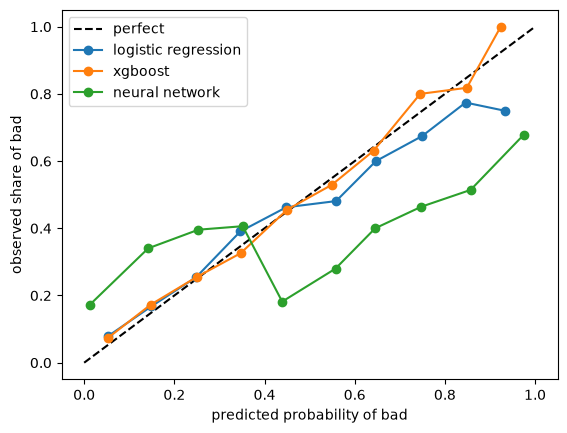

In [5]:
import matplotlib.pyplot as plt
from sklearn.calibration import calibration_curve
from sklearn.model_selection import StratifiedKFold, cross_val_predict

skf = StratifiedKFold(5, shuffle=True, random_state=SEED)
plt.plot([0, 1], [0, 1], "k--", label="perfect")
for name, m in models.items():
    p = cross_val_predict(m, X, y, cv=skf, method="predict_proba")[:, 1]
    frac, mean_p = calibration_curve(y, p, n_bins=10)
    plt.plot(mean_p, frac, marker="o", label=name)
plt.xlabel("predicted probability of bad")
plt.ylabel("observed share of bad")
plt.legend()
plt.show()